In [ ]:
import pandas as pd
import matplotlib as mtp

#pd.set_option('display.max_rows', None)      # toutes les lignes
#pd.set_option('display.max_columns', None)   # toutes les colonnes
#pd.set_option('display.width', None)         # pas de retour à la ligne forcé
#pd.set_option('display.max_colwidth', None)  # contenu des cellules en entier
pd.reset_option('display')

distance = pd.read_csv("../data/distances.csv")
schedule = pd.read_csv("../data/released_schedule.csv")

## Rapport Data Quality
Cette partie est dédiée à des opérations diverses afin d'observer la qualité de nos données, ainsi que pour mettre en place nos différentes théories et spécifications futures.

L'analyse suit cinq axes :
1. Valeurs manquantes et nulles : distances absentes, quantités à 0, poids et volumes manquants.
2. Valeurs aberrantes : distribution des quantités, poids et volumes, et besoins qui dépassent la capacité d'un camion.
3. Répartition des commandes par date : saisonnalité et charge selon les jours.
4. Lignes en double : besoins identiques répartis sur plusieurs quais.
5. Matériaux et fournisseurs : matériaux livrés par plusieurs fournisseurs.

Chaque axe se termine par une conclusion, et une synthèse en fin de partie relie ces constats aux choix faits pour la suite du projet.

### 1. Valeurs manquantes et nulles

#### Table distances

On vérifie la présence de NaN dans la distance pour les fournisseurs.


In [11]:
distance[distance.isnull().any(axis=1)]

,supplier_id,distance
1,SUP_00002,NaN
11,SUP_00012,NaN
29,SUP_00030,NaN
30,SUP_00031,NaN
46,SUP_00047,NaN
49,SUP_00050,NaN
83,SUP_00084,NaN
114,SUP_00115,NaN
129,SUP_00130,NaN
136,SUP_00137,NaN


11 fournisseurs sur 156 (environ 7 %) n'ont pas de distance renseignée. Or la distance est, avec le poids, l'une des deux entrées de la grille tarifaire : sans elle, le coût de transport de ces fournisseurs ne peut pas être calculé, ni avant ni après consolidation, et donc l'économie non plus.

Avant de décider comment traiter ces valeurs manquantes, il faut vérifier si ces fournisseurs ont réellement des besoins dans le planning.

#### Fournisseurs sans distance présents dans le planning

Liste des fournisseurs sans distance mais quand même présents dans le dataset "released_schedule".

In [12]:
# Fournisseur ayant des distances manquantes présent dans le planning de livraison
supplier_ids = distance[distance.isnull().any(axis=1)]['supplier_id'].unique()
schedule[schedule['supplier_id'].isin(supplier_ids)]

,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
3178,2026-11-17,SUP_00130,MAT_000903,PLT_002,ULP_0008,0.0,0.0,0.42,2026-09-16,2026-11-08
3308,2026-11-20,SUP_00130,MAT_000563,PLT_002,ULP_0008,10.0,142.9,1.20,2026-11-04,2026-11-08
3309,2026-11-26,SUP_00130,MAT_000563,PLT_002,ULP_0008,10.0,142.9,1.20,2026-11-04,2026-11-08
3310,2026-11-27,SUP_00130,MAT_000563,PLT_002,ULP_0008,10.0,142.9,1.20,2026-11-04,2026-11-08
5376,2026-11-17,SUP_00130,MAT_000010,PLT_001,ULP_0028,1.0,63.0,0.42,2026-11-04,2026-11-08


Seuls 2 des 11 fournisseurs sans distance ont des besoins dans le planning :

- SUP_00130 : 5 lignes vers deux usines (PLT_002 et PLT_001), dont une à quantité 0. Ce sont de petites livraisons.
- SUP_00047 : 1 seule ligne, le 1er janvier 2027, date que nous retirons dans le pipeline.

L'impact sur le projet est donc faible : en pratique, seul SUP_00130 est concerné.

**Choix retenu** : nous n'estimons pas ces distances et nous ne supprimons pas ces lignes. Les fournisseurs sans distance sont **flaggés** : leurs besoins restent dans le traitement, mais le produit final les signale comme « fournisseur sans distance ». Leur coût de transport et leur économie ne peuvent pas être chiffrés tant que la distance n'est pas renseignée.



#### Table released_schedule

On vérifie la présence de NaN ou de 0 dans la table schedule.

In [ ]:
schedule[schedule.isna().any(axis=1)]

,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
1303,2026-11-23,SUP_00046,MAT_000685,PLT_001,ULP_0051,0.0,NaN,NaN,2026-01-30,2026-11-08
1755,2026-11-10,SUP_00112,MAT_000611,PLT_004,ULP_0017,18.0,NaN,NaN,2026-11-06,2026-11-08
2120,2026-11-09,SUP_00109,MAT_000522,PLT_002,ULP_0025,271.0,NaN,NaN,2026-11-04,2026-11-08
2178,2026-12-08,SUP_00133,MAT_001031,PLT_002,ULP_0022,32.0,NaN,NaN,2026-11-04,2026-11-08
2354,2026-11-09,SUP_00117,MAT_000613,PLT_002,ULP_0022,30.0,NaN,NaN,2026-11-04,2026-11-08
...,...,...,...,...,...,...,...,...,...,...
5410,2026-12-14,SUP_00001,MAT_000333,PLT_004,ULP_0010,352.0,NaN,0.42,2026-11-06,2026-11-08
5411,2026-12-15,SUP_00001,MAT_000333,PLT_004,ULP_0010,208.0,NaN,0.42,2026-11-06,2026-11-08
5412,2026-12-17,SUP_00001,MAT_000333,PLT_004,ULP_0010,104.0,NaN,0.42,2026-11-06,2026-11-08
5413,2026-12-18,SUP_00001,MAT_000333,PLT_004,ULP_0010,176.0,NaN,0.42,2026-11-06,2026-11-08


In [17]:
# Nombre de lignes contenant des quantités à 0
n = (schedule["schedule_quantity"] == 0).sum()
print(f"{n} lignes à 0 ({n / len(schedule):.1%})")

zero_qty = schedule[schedule["schedule_quantity"] == 0]

# Valeur renseignée ET différente de 0
weight_ok = zero_qty["weight"].notna() & (zero_qty["weight"] != 0)
volume_ok = zero_qty["volume"].notna() & (zero_qty["volume"] != 0)

print(f"Lignes avec schedule_quantity == 0 : {len(zero_qty)}")
print(f"weight non null et != 0          : {weight_ok.sum()}")
print(f"volume non null et != 0          : {volume_ok.sum()}")
print(f"weight OU volume non null et != 0: {(weight_ok | volume_ok).sum()}")
print(f"weight ET volume non null et != 0: {(weight_ok & volume_ok).sum()}")

# Pour voir les lignes concernées
zero_qty[weight_ok | volume_ok].head(20)

918 lignes à 0 (17.3%)
Lignes avec schedule_quantity == 0 : 918
weight non null et != 0          : 0
volume non null et != 0          : 891
weight OU volume non null et != 0: 891
weight ET volume non null et != 0: 0


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
5,2026-11-17,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
11,2026-11-26,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
15,2026-12-02,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
20,2026-12-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
23,2026-12-15,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
34,2026-12-01,SUP_00022,MAT_000769,PLT_004,ULP_0050,0.0,0.0,1.2000,2026-09-01,2026-11-08
43,2026-12-02,SUP_00022,MAT_000422,PLT_004,ULP_0050,0.0,0.0,1.2000,2026-11-06,2026-11-08
51,2026-11-26,SUP_00003,MAT_000802,PLT_004,ULP_0050,0.0,0.0,0.5700,2026-10-02,2026-11-08


L'analyse révèle la présence de nombreuses valeurs NaN et 0 :

- Quantités à 0 : 959 lignes ont une schedule_quantity nulle, c'est-à-dire aucun besoin ce jour-là. Elles ne représentent aucune marchandise à transporter et seront retirées dans le pipeline (SF-02).
- NaN : 169 lignes contiennent au moins un NaN, uniquement dans les colonnes weight et volume. La plupart de ces lignes ont pourtant une quantité positive : il manque donc le poids ou le volume de vrais besoins.
- Une quantité à 0 n'entraîne pas forcément un poids NaN : certaines lignes à 0 ont un poids NaN, d'autres un poids égal à 0 (par exemple la ligne 3178 de SUP_00130 ci-dessus).

Le poids manquant est le point le plus gênant, car c'est lui qui détermine à la fois le remplissage du camion (24,5 t) et le prix dans la grille tarifaire. On remarque aussi que les NaN ne sont pas dispersés au hasard : certaines références n'ont jamais de poids (par exemple MAT_000333 de SUP_00001, sans poids sur plusieurs dates consécutives). Pour ces cas, on ne peut pas reprendre le poids d'une autre ligne de la même référence : il faudra soit l'estimer à partir du volume, soit exclure ces lignes ou les signaler.

### 2. Valeurs aberrantes

#### Distribution des quantités, poids et volumes


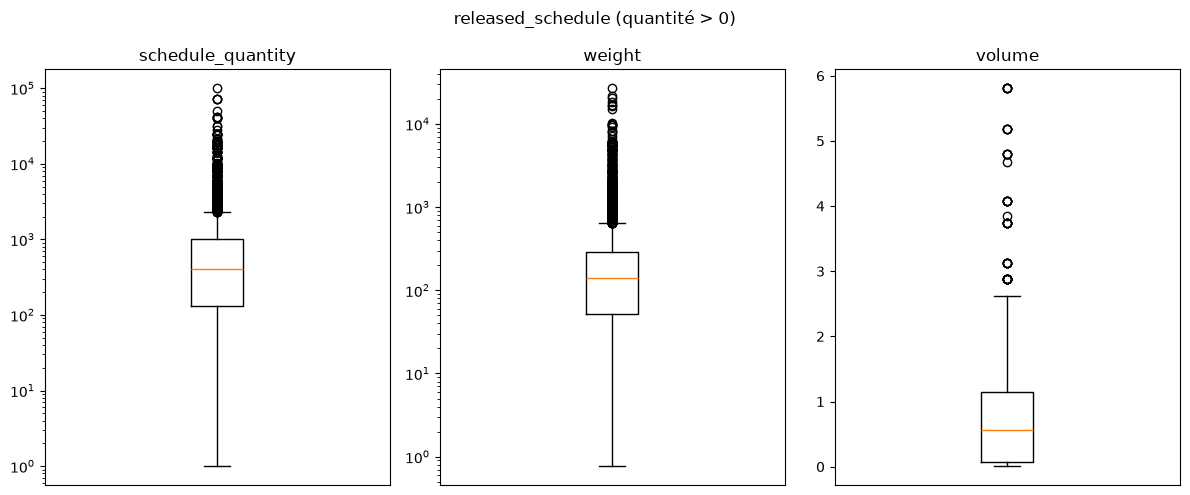

In [ ]:
import matplotlib.pyplot as plt

# --- schedule : une colonne par sous-graphique (les échelles sont très différentes) ---
cols = ["schedule_quantity", "weight", "volume"]
livraisons = schedule[schedule["schedule_quantity"] > 0]  # on enlève les jours sans livraison

fig, axes = plt.subplots(1, len(cols), figsize=(12, 5))
for ax, col in zip(axes, cols):
    ax.boxplot(livraisons[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])
    if col != "volume":
        ax.set_yscale("log")

fig.suptitle("released_schedule (quantité > 0)")
plt.tight_layout()
plt.show()

Les distributions de schedule_quantity et de weight sont très asymétriques. La plupart des livraisons sont petites (médiane de 400 pièces et 146 kg), mais il y a une longue traîne de valeurs élevées : selon la règle des 1,5 × IQR, 607 quantités (au-delà de 2 505 pièces) et 523 poids (au-delà de 698 kg) sont aberrants. Le volume est plus homogène : seules 53 valeurs dépassent 2,76 m³, avec un maximum de 5,8 m³.

Ces valeurs  correspondent surtout à de gros besoins ponctuels. Nous ne les supprimons donc pas, car les retirer reviendrait à oublier des besoins réels.



#### Dépassement de la capacité d'un camion (24,5 t)

On observe les valeurs de poids aberrantes par jour : d'abord les lignes seules, puis les couples fournisseur × usine × jour.

In [13]:
# Lignes seules > 24,5 T
schedule_higher_to_24 = schedule[schedule.weight > 24500].sort_values("weight", ascending=False)
schedule_higher_to_24

# couple jour dont le poids total dépasse 24,5 T
couple_day = (schedule.groupby(["supplier_id", "plant", "date"])[["weight", "volume"]]
                      .sum()
                      .reset_index())

big_couple_days = couple_day[couple_day.weight > 24500].sort_values("weight", ascending=False)
big_couple_days

,supplier_id,plant,date,weight,volume
515,SUP_00046,PLT_004,2026-11-11,46733.64,6.45408
518,SUP_00046,PLT_004,2026-12-02,32306.82,9.31872
778,SUP_00074,PLT_003,2026-12-15,29351.45,2.52000
517,SUP_00046,PLT_004,2026-11-25,26535.24,7.37568
364,SUP_00037,PLT_002,2026-11-27,25722.70,39.00800


- **Par ligne** : deux lignes dépassent 24,5 t à elles seules : SUP_00117 / MAT_000700 (58,3 t le 01/01/2027) et SUP_00074 / MAT_001164 (26,9 t le 15/12). Ces besoins demandent obligatoirement plus d'un camion, quelle que soit la consolidation.
- **Par couple** : 8 couples-jours dépassent 24,5 t.
  - Trois d'entre eux tombent le **1er janvier 2027** : SUP_00117 et PLT_004 (115,1 t), SUP_00085 et PLT_004 (37,5 t) et SUP_00024 et PLT_001 (25,5 t). Ces poids sont trop différent du reste du planning, ce qui confirme que cette date est anormale (voir la répartition par date ci-dessous).
  - Parmi les 5 autres, 3 concernent SUP_00046 → PLT_004 (46,7 t le 11/11, 32,3 t le 02/12, 26,5 t le 25/11). Pour ce fournisseur, le poids par pièce est d'environ 250 kg pour plusieurs références (par exemple 21,8 t pour 86 pièces de MAT_000486).

Ces cas restent rares (8 couples-jours sur environ 1 900), mais l'outil doit savoir découper un besoin sur plusieurs camions (SF-07). Ils ont aussi un effet sur le profil de livraison : pour SUP_00046, regrouper plusieurs jours dans un même camion sera souvent impossible, ce qui imposera une fréquence de livraison plus élevée que pour les autres couples.


### 3. Répartition des commandes par date

On regarde comment les lignes de besoin se répartissent sur l'horizon du planning.


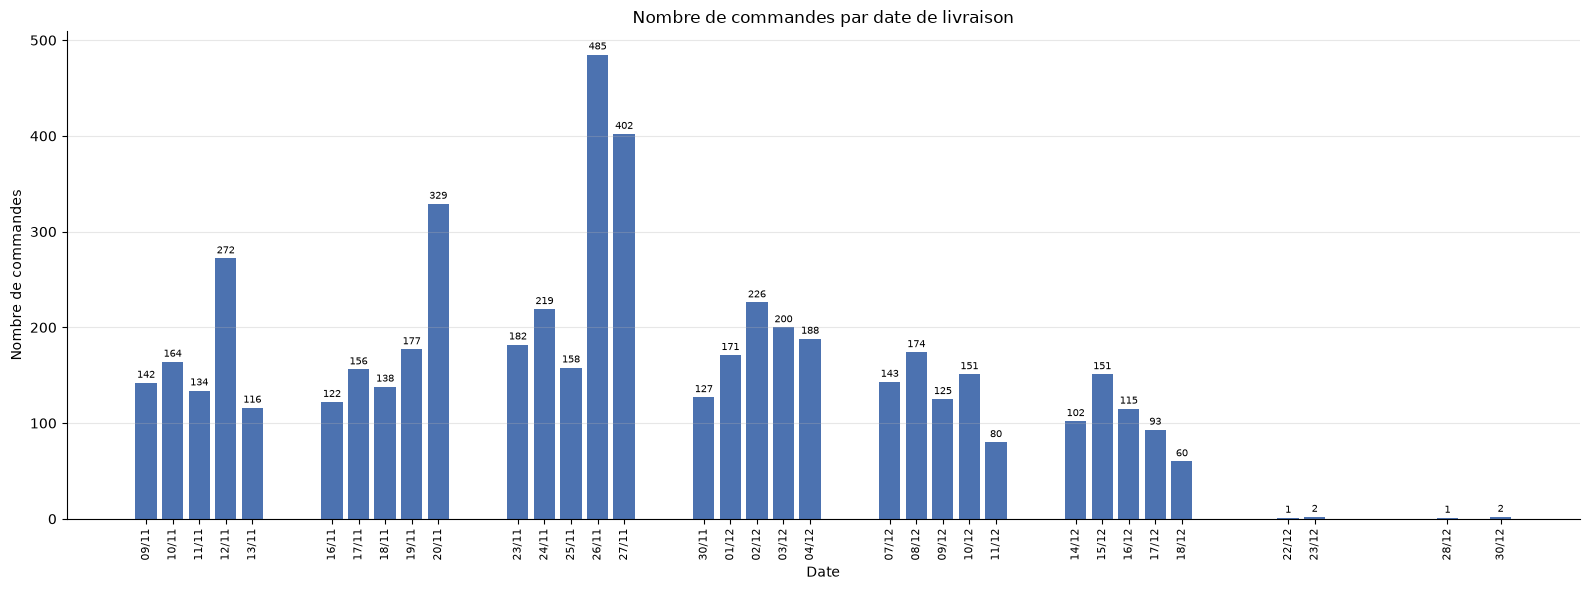

count     34.000000
mean     156.117647
std      103.063018
min        1.000000
25%      115.250000
50%      147.000000
75%      180.750000
max      485.000000
dtype: float64


In [14]:
# Répartition des commandes par date
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

commandes = schedule.copy()
commandes["date"] = pd.to_datetime(commandes["date"])
par_date = commandes.groupby("date").size()

fig, ax = plt.subplots(figsize=(16, 6))
barres = ax.bar(par_date.index, par_date.values, width=0.8, color="#4C72B0")

# Une étiquette de date sous chaque barre (uniquement les dates qui ont des commandes)
ax.set_xticks(par_date.index)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8)

# Nombre de commandes au-dessus de chaque barre
ax.bar_label(barres, fontsize=7, padding=2)

ax.set_title("Nombre de commandes par date de livraison")
ax.set_xlabel("Date")
ax.set_ylabel("Nombre de commandes")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(par_date.describe())

- **Jours ouvrés uniquement** : les livraisons n'ont lieu qu'en semaine, les week-ends n'apparaissent pas sur le graphique.
- **Charge moyenne** : sur les 35 dates du planning, on compte en moyenne environ 164 lignes par date, mais avec un fort écart-type (environ 111), ce qui montre une charge très irrégulière d'un jour à l'autre.
- **Pics** : les plus fortes journées tombent fin novembre (329 le 20/11, 485 le 26/11 et 402 le 27/11), plutôt en fin de semaine (jeudi et vendredi). Les lundis sont au contraire souvent plus calmes (par exemple 122 lignes le 16/11 et 102 le 14/12).
- **Fin d'année** : l'activité diminue au fil de décembre et devient quasi nulle après le 18/12 (1 à 2 lignes les 22, 23, 28 et 30/12), ce qui correspond à la période de fermeture de fin d'année.
- **1er janvier 2027** : la dernière date du planning repart brutalement à la hausse, alors que l'activité est quasi nulle depuis le 18/12 et que c'est un jour férié. Avec les poids anormaux relevés plus haut, cela ressemble à un report de tous les besoins situés au-delà de l'horizon du programme plutôt qu'à de vrais besoins : cette date est retirée dans le pipeline.

Ces écarts ont deux conséquences pour la suite :
1. **Lissage** : sans répartition des jours de livraison, certaines journées saturent les quais de réception pendant que d'autres restent presque vides. L'outil doit donc répartir les jours de livraison entre les couples d'une même usine (SF-08).
2. **Livraison en avance** : la possibilité de livrer jusqu'à 7 jours en avance (SF-06) permet de déplacer une partie des besoins des jours de pic vers des jours plus calmes, et de regrouper les petites livraisons de fin décembre.

### 4. Lignes en double (quai de déchargement)

Observation des lignes dupliquées sur les champs date, plant, material et supplier_id, afin d'analyser si des livraisons en double pourraient être évitées.

In [15]:

grouped = schedule.groupby(['date', 'plant', 'material', 'supplier_id']).agg(
    nb_rows=('supplier_id', 'size'),
    unloading_points=('unloading_point', lambda s: sorted(s.dropna().unique())),
    row_ids=('supplier_id', lambda s: list(s.index)),  # numéro de la ligne dans le fichier original
).reset_index()
grouped[grouped['nb_rows'] > 1]

,date,plant,material,supplier_id,nb_rows,unloading_points,row_ids
2,2026-11-09,PLT_001,MAT_000231,SUP_00052,2,"[ULP_0001, ULP_0044]","[1431, 4907]"
10,2026-11-09,PLT_001,MAT_000523,SUP_00102,2,"[ULP_0001, ULP_0006]","[1467, 2696]"
60,2026-11-09,PLT_002,MAT_000501,SUP_00091,2,"[ULP_0025, ULP_0038]","[2105, 5358]"
76,2026-11-09,PLT_002,MAT_000970,SUP_00080,2,"[ULP_0025, ULP_0038]","[2137, 5362]"
148,2026-11-10,PLT_001,MAT_000231,SUP_00052,2,"[ULP_0001, ULP_0044]","[1432, 4908]"
...,...,...,...,...,...,...,...
3873,2026-12-04,PLT_001,MAT_001085,SUP_00045,2,"[ULP_0001, ULP_0044]","[1464, 4973]"
4029,2026-12-07,PLT_001,MAT_001024,SUP_00045,2,"[ULP_0012, ULP_0044]","[4512, 4810]"
4146,2026-12-08,PLT_001,MAT_000598,SUP_00118,2,"[ULP_0001, ULP_0006]","[1387, 2676]"
4153,2026-12-08,PLT_001,MAT_000736,SUP_00107,2,"[ULP_0001, ULP_0044]","[1452, 4950]"


118 combinaisons date × usine × matériau × fournisseur apparaissent sur plusieurs lignes. Seul l'unloading point diffère, les autres colonnes sont identiques. On peut donc les agréger si le poids/volume ne dépasse pas les capacités du camion.

Ces lignes correspondent à une même référence, livrée le même jour par le même fournisseur à la même usine, mais sur plusieurs quais. Aujourd'hui, chaque ligne peut donner lieu à un transport distinct. En les regroupant dans un même camion, avec plusieurs points de déchargement dans l'usine, on supprime des trajets sans rien changer au besoin. C'est un premier gain de consolidation, avant même de regrouper plusieurs jours entre eux.

Le quai doit toutefois être conservé dans la sortie 2 (contenu de chaque camion, SF-10), pour que l'usine sache où décharger chaque partie de la livraison.

### 5. Matériaux et fournisseurs


On cherche à déterminer si des valeurs aberrantes sont observées dans la distribution des matériaux en fonction des différents fournisseurs.

In [16]:
# Pour chaque matériau, ses fournisseurs associés
mat = schedule.groupby('material')['supplier_id'].unique().apply(list)

# Matériaux vendus par plusieurs fournisseurs (tous les autres n'en ont qu'un)
multi_suppliers = mat[mat.apply(len) > 1]
multi_suppliers

material
MAT_000072    [SUP_00035, SUP_00057, SUP_00156]
MAT_000239               [SUP_00035, SUP_00057]
MAT_000254               [SUP_00102, SUP_00094]
MAT_000298               [SUP_00146, SUP_00085]
MAT_000429               [SUP_00085, SUP_00146]
MAT_000433               [SUP_00146, SUP_00085]
MAT_000455               [SUP_00085, SUP_00146]
MAT_000505               [SUP_00085, SUP_00146]
MAT_000519               [SUP_00035, SUP_00057]
MAT_000646               [SUP_00085, SUP_00146]
MAT_000805               [SUP_00124, SUP_00144]
MAT_000808               [SUP_00085, SUP_00146]
MAT_000906               [SUP_00085, SUP_00146]
MAT_000919               [SUP_00035, SUP_00057]
MAT_000949               [SUP_00085, SUP_00146]
MAT_000956               [SUP_00035, SUP_00156]
MAT_000966               [SUP_00085, SUP_00146]
Name: supplier_id, dtype: object

Pas d'aberration observée dans cette distribution. La grande majorité des matériaux n'a qu'un seul fournisseur : seuls 18 matériaux sont livrés par plusieurs fournisseurs, 17 par 2 fournisseurs et MAT_000072 par 3.

On retrouve souvent les mêmes groupes de fournisseurs :
- **SUP_00085 / SUP_00146** partagent 10 références ;
- **SUP_00035 / SUP_00057** en partagent 4 (dont MAT_000072, aussi livré par SUP_00156) ;
- les autres paires (SUP_00102 / SUP_00094, SUP_00066 / SUP_00015, SUP_00124 / SUP_00144, SUP_00035 / SUP_00156) ne partagent qu'une seule référence.

Ces fournisseurs semblent donc interchangeables pour ces références. Le choix du fournisseur n'entre pas dans le périmètre du projet (on consolide par couple fournisseur × usine, sans modifier qui livre quoi), mais c'est une piste d'optimisation supplémentaire : concentrer ces références chez un seul fournisseur permettrait de mieux remplir ses camions.


### Synthèse de l'analyse

#### Principaux constats

| Axe | Constat | Conséquence pour le projet |
|---|---|---|
| Distances | 11 fournisseurs sans distance, dont 2 présents dans le planning (en pratique, seul SUP_00130 est concerné) | Fournisseurs flaggés « sans distance » dans le produit final, non chiffrés |
| Quantités nulles | 959 lignes (16,7 %) sans besoin | Lignes retirées dans le pipeline (SF-02) |
| Poids et volumes manquants | 169 lignes avec des NaN, dont des références sans aucun poids | Poids à estimer ou lignes exclues et signalées |
| Valeurs aberrantes | Distributions très asymétriques, mais valeurs plausibles | Valeurs conservées pour ne perdre aucun besoin (SF-12) |
| Capacité camion | 2 lignes et 8 couples-jours au-delà de 24,5 t (dont 3 le 01/01/2027) ; Découpage sur plusieurs camions (SF-07) ; poids à vérifier |
| Calendrier | Jours ouvrés uniquement, pics fin novembre, quasi-arrêt après le 18/12 | Lissage (SF-08) et livraison en avance (SF-06) |
| 1er janvier 2027 | Reprise brutale en fin d'horizon, un jour férié, avec des poids anormaux (jusqu'à 115 t pour un couple) | Date retirée dans le pipeline |
| Doublons de quai | 118 besoins répartis sur plusieurs quais | Regroupement dans un même camion, quai conservé (SF-10) |
| Matériaux | 18 matériaux avec plusieurs fournisseurs | Piste d'optimisation hors périmètre |

#### Conclusion

Les données sont globalement exploitables : la structure est propre (pas de doublon sur la clé, pas de fournisseur absent du référentiel des distances) et les anomalies relevées concernent une part limitée des lignes. Deux points demandent cependant une décision avant le calcul des coûts, et un troisième est traité par un flag :
1. **les poids manquants**, car le poids conditionne à la fois le remplissage des camions et le prix ;
2. **les poids lourd de SUP_00046**, qui nécessiteront + de livraisons que d'autres pièces du au poids elevé à mettre dans les camions;
3. **la distance manquante de SUP_00130** : le fournisseur est flaggé comme « sans distance » dans le produit final, et ses livraisons ne sont pas chiffrées.

Surtout, l'analyse confirme l'intérêt du projet : avec un poids médian de 146 kg par ligne pour une capacité de 24,5 t, les livraisons actuelles sont très fragmentées. Regrouper les besoins par couple fournisseur × usine, sur plusieurs jours et sur plusieurs quais, devrait permettre de réduire fortement le nombre de camions et donc le coût de transport.

Ces constats servent de base aux hypothèses, aux spécifications et au pipeline de traitement présentés dans la suite.

## Liste des Spécifications, Hypothèses et contraintes


À partir de nos observations précédentes, nous avons regroupé plusieurs hypothèses durant nos réflexions :

- On regroupe plusieurs lignes par semaine en une seule, où chacune a un volume attribué (un contenant) qui n’est peut-être pas utilisé à sa pleine capacité. N’ayant pas plus d’information sur le volume total et occupé du contenant, on suppose qu'on ne peut regrouper les volumes, nos estimations seront donc majorées.

- Un même matériau peut être vendu par plusieurs fournisseurs. Notre tâche s’arrête à l’optimisation des lignes, mais pour aller plus loin nous pourrions également optimiser le choix du fournisseur pour un matériau et une usine donnée.


In [ ]:
# les materiaux vendus par plusieurs fournisseurs
materials = schedule.groupby('material')['supplier_id'].agg(
    nb_suppliers='nunique',
    suppliers=lambda s: sorted(s.dropna().unique())
)
multi_suppliers = materials[materials['nb_suppliers'] > 1]
multi_suppliers

- Le poids renseigné est le poids total correspondant au poids fixe du volume et de la quantité de pièces × le poids unitaire de la pièce.
- Les livraisons du 1er janvier sont un cas unique car l'anticipation sur plusieurs semaines à l'avenir mettent les besoins au 1er du mois d'après
-

À la suite de la mise en place de nos différentes hypothèses, nous avons relevé des spécifications propres au projet :

- SF-01 : L’outil importe le planning (CSV), les distances (CSV) et la grille tarifaire (PDF).

- SF-02 : L’outil ne prend en compte que les lignes avec une quantité supérieure à 0.

- SF-03 : L’outil consolide les besoins par couple fournisseur × usine, jamais deux usines dans un même camion.

- SF-04 : L’outil attribue à chaque couple un profil de livraison : une fréquence (1, 2, 3 ou 5 fois par semaine) et des jours fixes.

- SF-05 : L’outil retient la fréquence la plus basse possible qui respecte les contraintes.

- SF-06 : Un besoin peut être livré en avance, de 7 jours au maximum, mais jamais en retard.

- SF-07 : Un camion ne dépasse jamais 24,5 t ni 110,4 m³. Au-delà, l’outil ajoute un camion.

- SF-08 : L’outil répartit les jours de livraison entre les couples d’une même usine (lissage).

- SF-09 : L’outil produit la sortie 1, le profil de chaque couple.

- SF-10 : L’outil produit la sortie 2, le contenu de chaque camion (materials, quai, quantité, poids, volume).

- SF-11 : L’outil produit la sortie 3, l’économie par couple, en € et en %.

- SF-12 : Chaque ligne de besoin est livrée une fois et une seule, sans oubli ni doublon.

- SF-13 : Les résultats sont consultables et exportables.


## Dictionnaire des données

#### Table `distances.csv`
Distance entre chaque fournisseur et le point de consolidation. 156 lignes, une par fournisseur.

| Champ | Description | Type | Contraintes | Exemple |
|---|---|---|---|---|
| supplier_id | Identifiant du fournisseur | Texte | Clé primaire, unique, non nul | SUP_00001 |
| distance | Distance fournisseur → point de consolidation | Décimal | ≥ 0, peut être nul | 47 |

#### Table `released_schedule.csv`
Programme de livraison (release schedule) envoyé aux fournisseurs. 5 728 lignes, une par date × fournisseur × article × usine × quai.

| Champ | Description | Type | Contraintes | Exemple |
|---|---|---|---|---|
| date | Date de livraison demandée | Date | Non nul | 2026-11-11 |
| supplier_id | Fournisseur qui expédie | Texte | Clé étrangère → distances.supplier_id | SUP_00091 |
| material | Référence de la pièce | Texte | Non nul | MAT_000110 |
| plant | Usine de destination | Texte | Non nul | PLT_004 |
| unloading_point | Quai de déchargement dans l'usine | Texte | Non nul | ULP_0027 |
| schedule_quantity | Quantité à livrer | Décimal | ≥ 0 ; 0 = pas de besoin | 5 000 |
| weight | Poids de la ligne | Décimal | ≥ 0, peut être nul | 92,6 |
| volume | Volume de la ligne | Décimal | > 0, peut être nul | 0,4116 |
| transmission_date | Date d'envoi du programme au fournisseur | Date | Non nul, ≤ version_date | 2026-11-06 |
| version_date | Version du programme | Date | Valeur unique | 2026-11-08 |

#### Clés et relations
| Élément | Définition |
|---|---|
| Clé primaire schedule | (date, supplier_id, material, plant, unloading_point), sans doublon |
| Clé de consolidation | fournisseur × usine × date |



## Pipeline de traitement

Le pipeline part du fichier brut `input/released_schedule.csv` et produit le même fichier, nettoyé, dans `output/released_schedule.csv`.

- `schedule` : les données brutes lues depuis le CSV d'entrée, jamais modifiées.
- `schedule_clean` : une copie de `schedule`, qui sera notre sortie. Tous les traitements s'appliquent sur cette variable.

### Schedule

#### Chargement des données d'entrée

In [45]:
INPUT_PATH = "../input/released_schedule.csv"
OUTPUT_PATH = "../output/released_schedule_cleaned.csv"

# Données brutes : on n'y touche plus après la lecture
schedule = pd.read_csv(INPUT_PATH)

# Copie de travail : c'est sur elle que s'appliquent tous les traitements, et c'est elle qu'on exporte
schedule_clean = schedule.copy()
schedule_clean["date"] = pd.to_datetime(schedule_clean["date"])

print(f"Nombre de lignes en entrée : {len(schedule)}")

Nombre de lignes en entrée : 5728


#### 1. Lignes avec une quantité nulle

In [42]:
nb_avant = len(schedule_clean)

# On ne garde que les lignes avec une quantité strictement supérieure à 0
schedule_clean = schedule_clean[schedule_clean["schedule_quantity"] > 0]

nb_apres = len(schedule_clean)
nb_supprimees = nb_avant - nb_apres

print(f"Nombre de lignes avant filtrage : {nb_avant}")
print(f"Nombre de lignes après filtrage : {nb_apres}")
print(f"Nombre de lignes supprimées (quantité <= 0) : {nb_supprimees}")

Nombre de lignes avant filtrage : 4769
Nombre de lignes après filtrage : 4769
Nombre de lignes supprimées (quantité <= 0) : 0


Nous avons choisi de ne garder que les lignes dont la quantité est strictement supérieure à 0, car une quantité nulle signifie l'absence de besoin de livraison ce jour-là. Ce choix est cohérent avec les données : sur ces 959 lignes, le poids est systématiquement égal à 0. Après filtrage, nous retrouvons bien le même nombre de lignes que dans l'énoncé (4 769 lignes sur 5 728).

#### 2. Entrées du 1er janvier 2027

In [43]:
nb_avant = len(schedule_clean)

# On supprime toutes les entrées du 1er janvier 2027
schedule_clean = schedule_clean[schedule_clean["date"] != "2027-01-01"]

nb_apres = len(schedule_clean)
nb_supprimees = nb_avant - nb_apres

print(f"Nombre de lignes avant filtrage : {nb_avant}")
print(f"Nombre de lignes après filtrage : {nb_apres}")
print(f"Nombre de lignes supprimées (1er janvier 2027) : {nb_supprimees}")
print(f"Dernière date du planning : {schedule_clean['date'].max():%Y-%m-%d}")

Nombre de lignes avant filtrage : 4769
Nombre de lignes après filtrage : 4390
Nombre de lignes supprimées (1er janvier 2027) : 379
Dernière date du planning : 2026-12-18


#### Export du fichier nettoyé

In [46]:
# Même format que le fichier d'entrée : mêmes colonnes, dates au format AAAA-MM-JJ, sans l'index
schedule_clean.to_csv(OUTPUT_PATH, index=False, date_format="%Y-%m-%d")

print(f"Fichier exporté : {OUTPUT_PATH}")
print(f"Nombre de lignes en sortie : {len(schedule_clean)} (sur {len(schedule)} en entrée)")

Fichier exporté : ../output/released_schedule_cleaned.csv
Nombre de lignes en sortie : 5728 (sur 5728 en entrée)
